# Assignment 2 – 246051T,246050N

### Research Title

Evaluating Machine Learning Models for Stroke
Prediction Based on Clinical Variables

**Research Article:** Akinwumi et al. (2025)

**Journal:** Frontiers in Neurology

**Dataset:** Stroke Prediction Dataset



# Research Article Selection

## Selected Research Article

Title: Evaluating Machine Learning Models for
Stroke Prediction Based on Clinical Variables

Authors: Patrick O. Akinwumi, Stephen Ojo,
Thomas I. Nathaniel, James Wanliss,
Olukayode Karunwi, and Mercy Sulaiman.

Journal: Frontiers in Neurology

Year: 2025

SOURCE: https://doi.org/10.3389/fneur.2025.1668420

## Reason for Selecting the Article

This research article was selected because it
compares five supervised machine learning
algorithms for stroke prediction.

The article uses a publicly available dataset,
allowing the experiments to be independently
implemented and evaluated.

The selected algorithms are also relevant to
the machine learning techniques studied in
the DA2111 module.

The article provides an opportunity to reproduce
existing findings and investigate improvements
through preprocessing, class imbalance handling,
cross-validation, and hyperparameter tuning.

## Research Objectives

The main objectives of this project are:

1. To investigate the application of machine
   learning algorithms for stroke prediction.

2. To reproduce the five machine learning
   algorithms used in the selected research paper.

3. To perform exploratory data analysis and
   appropriate preprocessing on the dataset.

4. To evaluate model performance using suitable
   classification metrics.

5. To investigate Random Oversampling and
   Class Weighting techniques to address
   class imbalance.

6. To identify the best-performing model and
   optimize its hyperparameters.

7. To compare the experimental results with
   those reported in the original research paper.

# Literature Review

## Research Article Summary

Stroke is a major cause of disability, creating a need for methods that can identify individuals at elevated risk. Akinwumi et al. (2025) investigated five supervised machine learning algorithms for stroke prediction using demographic, clinical, and lifestyle variables. The study used the Stroke Prediction Dataset from Kaggle. The dataset contains 5,110 records and 12 columns, including an identifier, ten predictor variables, and the stroke outcome. Predictors include gender, age, hypertension, heart disease, marital status, work type, residence type, average glucose level, body mass index (BMI), and smoking status. There were 249 stroke cases (4.87%) and 4,861 non-stroke cases (95.13%), showing class imbalance. The BMI variable contained 201 missing values, which the authors handled using mean imputation.

The algorithms compared were Logistic Regression, Random Forest, Gradient Boosting, Support Vector Machine (SVM), and K-Nearest Neighbours (KNN). The study describes categorical encoding, feature scaling, random oversampling to balance the training data, an 80:20 train-test split, and stratified five-fold cross-validation. Model performance was assessed using accuracy, ROC-AUC, and confusion matrices. The reported results showed high accuracy, 94.18% to 95.12%, and ROC-AUC values of 0.60 to 0.84. However, the confusion matrices revealed very limited detection of stroke cases: Logistic Regression, SVM, and Random Forest recorded no true positives, while Gradient Boosting and KNN each identified only one. This demonstrates that high accuracy can be misleading when the positive class is rare.

Random Forest feature-importance analysis identified age, average glucose level, and BMI as the most influential predictors. In this assignment, the five algorithms are implemented in Python and evaluated using a held-out test set and stratified cross-validation. Further experiments examine random oversampling, class-weighted learning, hyperparameter tuning, and threshold selection. These methods are assessed for minority-class detection, precision, and false-positive predictions. Results are exploratory within this dataset and do not establish causation or clinical diagnostic validity.

In [76]:
import pandas as pd

df = pd.read_csv("healthcare-dataset-stroke-data.csv")

df.head()


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [77]:
df.shape


(5110, 12)

In [78]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


### Dataset Overview

The Stroke Prediction Dataset contains 5,110 observations and 12 columns. It includes clinical and demographic information such as age, gender, hypertension, heart disease, average glucose level, BMI, and smoking status.

The target variable is "stroke", which has two classes:
- 0: No stroke
- 1: Stroke

The dataset will be used to develop and evaluate machine learning classification models.

In [79]:
# Check missing values in each column
df.isnull().sum()


,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


In [80]:
df.duplicated().sum()


np.int64(0)

In [81]:
# Check duplicates excluding patient ID
df.drop(columns=["id"]).duplicated().sum()


np.int64(0)

### Data Quality Assessment

The dataset was examined for missing values and duplicate records.

The BMI column contains 201 missing values. Therefore, an appropriate missing-value handling technique is required before model training.

Duplicate records were also checked to identify potential data quality issues.

In [82]:
# Count stroke and non-stroke patients
df['stroke'].value_counts()


,count
stroke,
0,4861
1,249


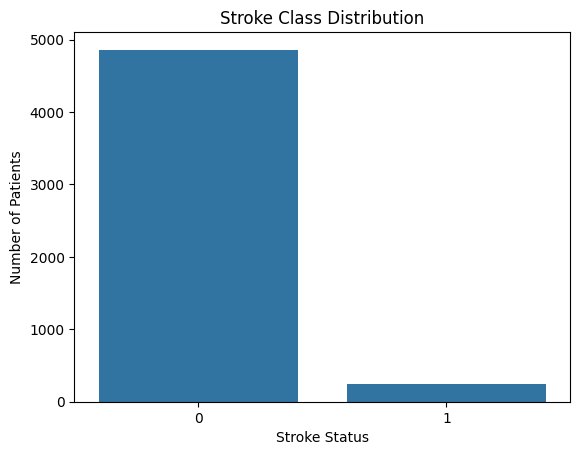

In [83]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create stroke distribution graph
sns.countplot(data=df, x='stroke')

plt.title('Stroke Class Distribution')
plt.xlabel('Stroke Status')
plt.ylabel('Number of Patients')

plt.show()


In [84]:
# Calculate class percentages
df['stroke'].value_counts(normalize=True) * 100


,proportion
stroke,
0,95.127202
1,4.872798


### Class Distribution Analysis

The distribution of the target variable was examined to identify potential class imbalance.

The dataset contains 4,861 non-stroke cases (95.13%) and 249 stroke cases (4.87%).

This indicates a significant class imbalance, which may affect the model's ability to identify stroke cases.

Therefore, accuracy alone may not be sufficient to evaluate model performance. Additional evaluation metrics such as precision, recall, and F1-score will be considered. Class imbalance handling techniques will also be investigated during model improvement.


In [85]:

# Descriptive statistics for numerical columns
df.describe()


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [86]:
# Summary of important numerical variables
df[['age', 'avg_glucose_level', 'bmi']].describe()


,age,avg_glucose_level,bmi
count,5110.000000,5110.000000,4909.000000
mean,43.226614,106.147677,28.893237
std,22.612647,45.283560,7.854067
min,0.080000,55.120000,10.300000
25%,25.000000,77.245000,23.500000
50%,45.000000,91.885000,28.100000
75%,61.000000,114.090000,33.100000
max,82.000000,271.740000,97.600000


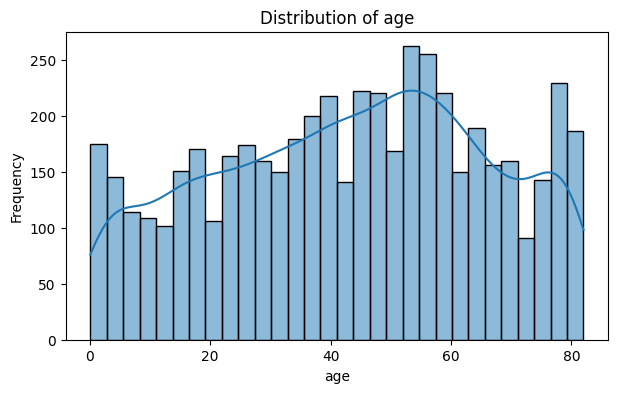

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distribution of age
plt.figure(figsize=(7, 4))
sns.histplot(df['age'].dropna(), bins=30, kde=True)

plt.title('Distribution of age')
plt.xlabel('age')
plt.ylabel('Frequency')
plt.show()


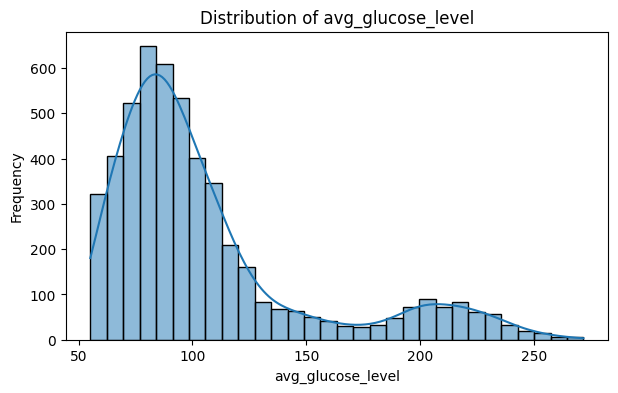

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distribution of avg_glucose_level
plt.figure(figsize=(7, 4))
sns.histplot(df['avg_glucose_level'].dropna(), bins=30, kde=True)

plt.title('Distribution of avg_glucose_level')
plt.xlabel('avg_glucose_level')
plt.ylabel('Frequency')
plt.show()


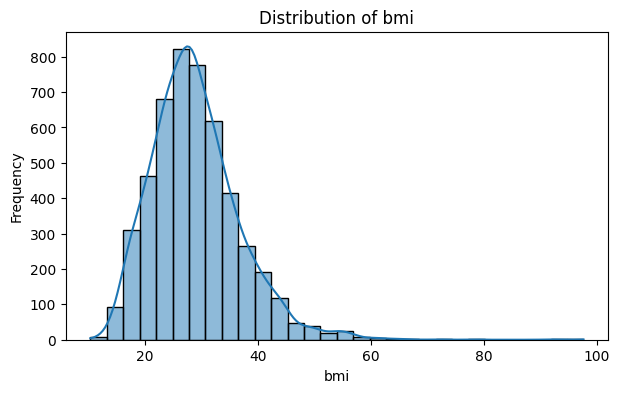

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distribution of bmi
plt.figure(figsize=(7, 4))
sns.histplot(df['bmi'].dropna(), bins=30, kde=True)

plt.title('Distribution of bmi')
plt.xlabel('bmi')
plt.ylabel('Frequency')
plt.show()


### Descriptive Statistical Analysis

Descriptive statistics were used to examine the numerical variables, including age, average glucose level, and BMI.

Measures such as mean, standard deviation, minimum, maximum, and quartiles were calculated.

Histograms were also used to visualize the distributions of these variables and identify possible skewness and unusual values.

These findings will help guide appropriate preprocessing techniques before model training.

In [88]:
# Compare numerical variables by stroke status
df.groupby('stroke')[['age', 'avg_glucose_level', 'bmi']].mean()


,age,avg_glucose_level,bmi
stroke,,,
0,41.971545,104.795513,28.823064
1,67.728193,132.544739,30.471292


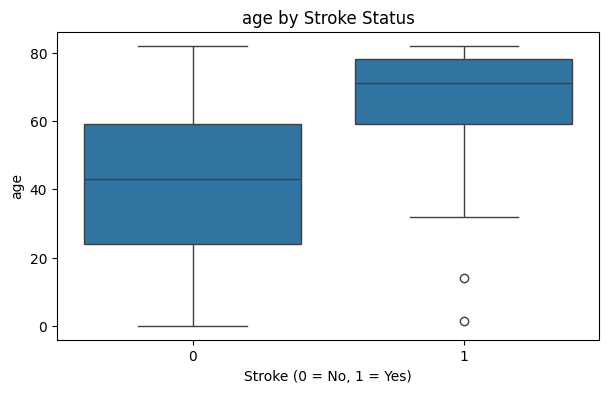

In [89]:
import matplotlib.pyplot as plt
import seaborn as sns

# age by stroke status
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='stroke', y='age')
plt.title('age by Stroke Status')
plt.xlabel('Stroke (0 = No, 1 = Yes)')
plt.ylabel('age')
plt.show()


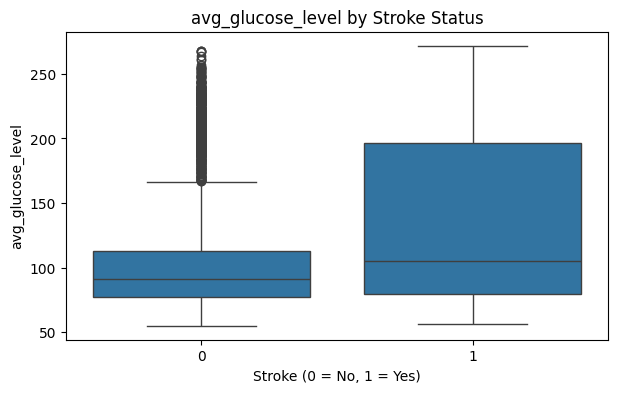

In [89]:
import matplotlib.pyplot as plt
import seaborn as sns

# avg_glucose_level by stroke status
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='stroke', y='avg_glucose_level')
plt.title('avg_glucose_level by Stroke Status')
plt.xlabel('Stroke (0 = No, 1 = Yes)')
plt.ylabel('avg_glucose_level')
plt.show()


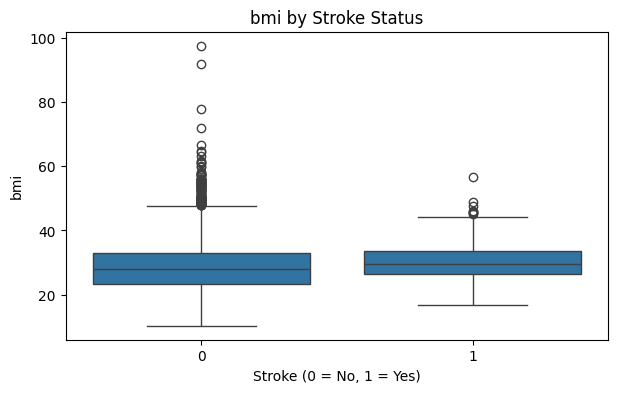

In [89]:
import matplotlib.pyplot as plt
import seaborn as sns

# bmi by stroke status
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x='stroke', y='bmi')
plt.title('bmi by Stroke Status')
plt.xlabel('Stroke (0 = No, 1 = Yes)')
plt.ylabel('bmi')
plt.show()


### Comparison of Numerical Variables by Stroke Status

The distributions of age, average glucose level, and BMI were compared between stroke and non-stroke groups using boxplots.

Group means were also calculated to identify possible differences between the two classes.

These comparisons help explore potential relationships between clinical variables and stroke status.

In [90]:

# Categorical variables
categorical_cols = [
    'gender',
    'ever_married',
    'work_type',
    'Residence_type',
    'smoking_status'
]

# Percentage of stroke cases in each category
for col in categorical_cols:
    print(f"\n{col}")
    print(
        df.groupby(col)['stroke'].mean() * 100
    )



gender
gender
Female    4.709419
Male      5.106383
Other     0.000000
Name: stroke, dtype: float64

ever_married
ever_married
No     1.650541
Yes    6.561288
Name: stroke, dtype: float64

work_type
work_type
Govt_job         5.022831
Never_worked     0.000000
Private          5.094017
Self-employed    7.936508
children         0.291121
Name: stroke, dtype: float64

Residence_type
Residence_type
Rural    4.534606
Urban    5.200308
Name: stroke, dtype: float64

smoking_status
smoking_status
Unknown            3.044041
formerly smoked    7.909605
never smoked       4.756871
smokes             5.323194
Name: stroke, dtype: float64


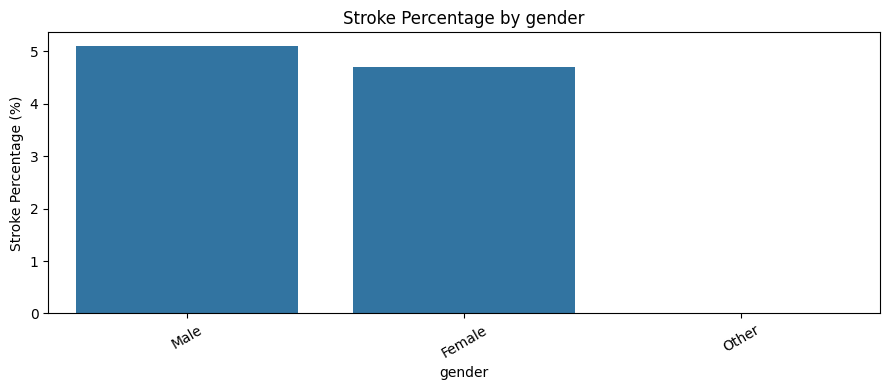

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns

# Stroke percentage by gender
plt.figure(figsize=(9, 4))

stroke_rates = (
    df.groupby('gender')['stroke']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

sns.barplot(
    x=stroke_rates.index,
    y=stroke_rates.values
)

plt.title('Stroke Percentage by gender')
plt.xlabel('gender')
plt.ylabel('Stroke Percentage (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


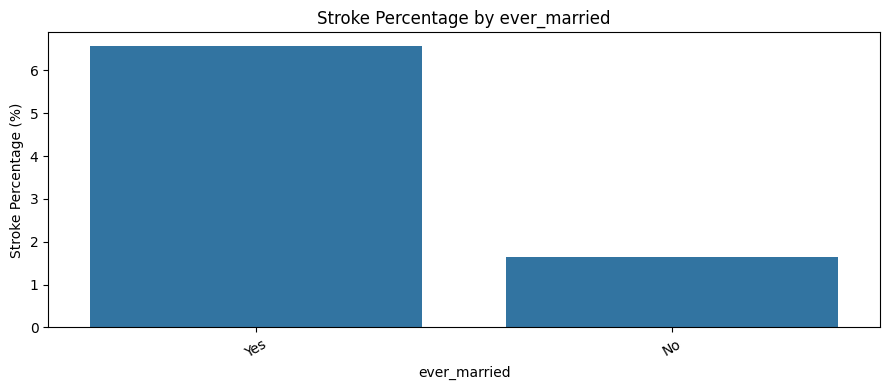

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns

# Stroke percentage by ever_married
plt.figure(figsize=(9, 4))

stroke_rates = (
    df.groupby('ever_married')['stroke']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

sns.barplot(
    x=stroke_rates.index,
    y=stroke_rates.values
)

plt.title('Stroke Percentage by ever_married')
plt.xlabel('ever_married')
plt.ylabel('Stroke Percentage (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


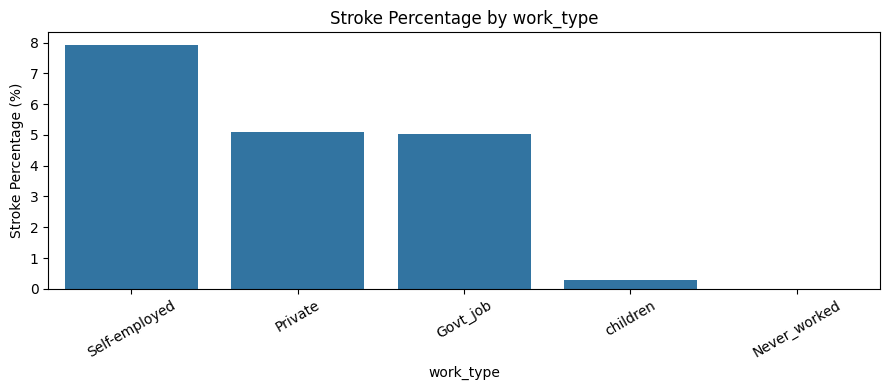

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns

# Stroke percentage by work_type
plt.figure(figsize=(9, 4))

stroke_rates = (
    df.groupby('work_type')['stroke']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

sns.barplot(
    x=stroke_rates.index,
    y=stroke_rates.values
)

plt.title('Stroke Percentage by work_type')
plt.xlabel('work_type')
plt.ylabel('Stroke Percentage (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


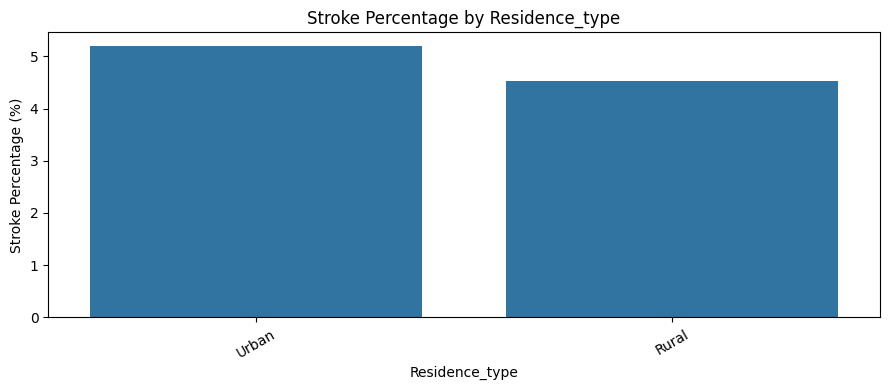

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns

# Stroke percentage by Residence_type
plt.figure(figsize=(9, 4))

stroke_rates = (
    df.groupby('Residence_type')['stroke']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

sns.barplot(
    x=stroke_rates.index,
    y=stroke_rates.values
)

plt.title('Stroke Percentage by Residence_type')
plt.xlabel('Residence_type')
plt.ylabel('Stroke Percentage (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


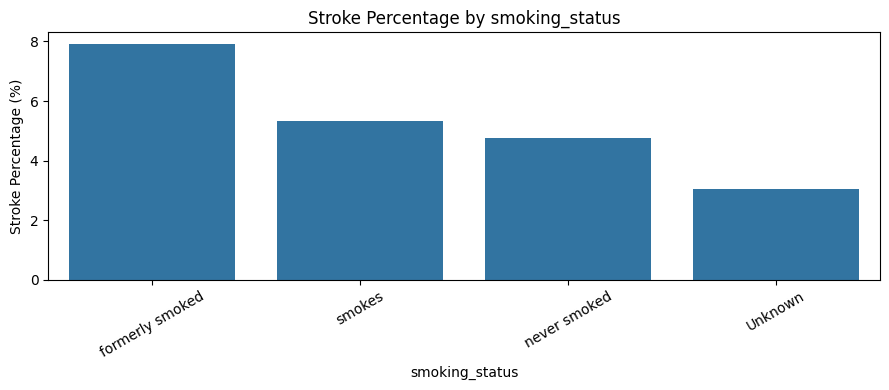

In [91]:
import matplotlib.pyplot as plt
import seaborn as sns

# Stroke percentage by smoking_status
plt.figure(figsize=(9, 4))

stroke_rates = (
    df.groupby('smoking_status')['stroke']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

sns.barplot(
    x=stroke_rates.index,
    y=stroke_rates.values
)

plt.title('Stroke Percentage by smoking_status')
plt.xlabel('smoking_status')
plt.ylabel('Stroke Percentage (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


### Categorical Variable Analysis

Categorical variables, including gender, marital status, work type, residence type, and smoking status, were analyzed.

Bar charts were used to compare the percentage of stroke cases across different categories.

This analysis helped identify possible associations between categorical variables and stroke status. These associations do not necessarily indicate causation.

In [92]:

# Select numerical variables
numeric_cols = [
    'age', 'hypertension', 'heart_disease',
    'avg_glucose_level', 'bmi', 'stroke'
]

# Calculate correlation matrix
corr_matrix = df[numeric_cols].corr()

corr_matrix


,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
age,1.000000,0.276398,0.263796,0.238171,0.333398,0.245257
hypertension,0.276398,1.000000,0.108306,0.174474,0.167811,0.127904
heart_disease,0.263796,0.108306,1.000000,0.161857,0.041357,0.134914
avg_glucose_level,0.238171,0.174474,0.161857,1.000000,0.175502,0.131945
bmi,0.333398,0.167811,0.041357,0.175502,1.000000,0.042374
stroke,0.245257,0.127904,0.134914,0.131945,0.042374,1.000000


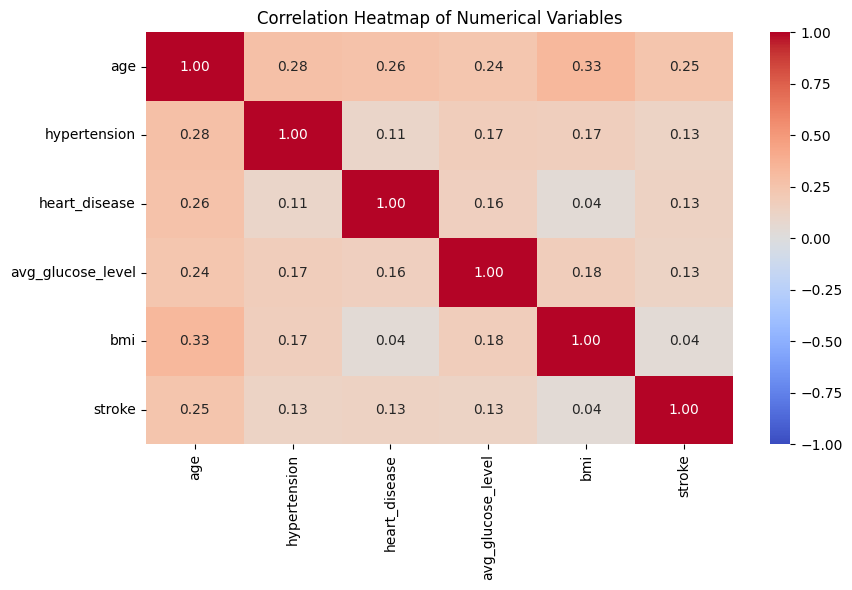

In [93]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()


### Correlation Analysis

A correlation matrix was calculated to examine relationships among numerical variables.

A heatmap was used to visualize the strength and direction of these relationships.

Correlation values range from -1 to +1. Values closer to +1 indicate stronger positive relationships, while values closer to -1 indicate stronger negative relationships.

The analysis helps identify potential relationships between numerical features and stroke status. However, correlation does not imply causation.

In [94]:

# Separate independent and dependent variables
X = df.drop(columns=['id', 'stroke'])
y = df['stroke']

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (5110, 10)
Target shape: (5110,)


In [95]:
#Split Training and Testing Data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 4088
Testing samples: 1022


### Data Preprocessing – Feature Selection and Data Splitting

The patient ID column was removed because it is not a meaningful predictor of stroke.

The dataset was divided into independent variables (X) and the target variable (y).

An 80:20 stratified train-test split was applied with a random state of 42 for reproducibility.

Stratification was used to preserve the proportion of stroke and non-stroke cases in both datasets.

All preprocessing parameters will be learned from the training data to avoid data leakage.

In [96]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical and categorical columns
numeric_features = [
    'age', 'hypertension', 'heart_disease',
    'avg_glucose_level', 'bmi'
]

categorical_features = [
    'gender', 'ever_married', 'work_type',
    'Residence_type', 'smoking_status'
]

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created!")


Preprocessing pipeline created!


In [97]:

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using training parameters
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)


Training shape: (4088, 21)
Testing shape: (1022, 21)


### Handling Missing Values and Encoding

Missing numerical values were handled using median imputation.

Numerical variables were standardized using StandardScaler, while categorical variables were transformed using One-Hot Encoding.

A preprocessing pipeline was created to ensure consistent transformations.

The preprocessing pipeline was fitted only on the training data and then applied to the test data to prevent data leakage.

This section uses our own preprocessing (median imputation and StandardScaler) for the initial baseline models. A separate paper-based pipeline (mean imputation and MinMaxScaler), matching Akinwumi et al. (2025), is used later for the replication.

In [98]:
#train the model

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create model with preprocessing
lr_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train model
lr_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")


Logistic Regression trained successfully!


In [99]:
#make predictions

# Predict on test data
y_pred_lr = lr_model.predict(X_test)

print("Predictions completed!")


Predictions completed!


In [100]:
#evaluate model performance

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Predict probabilities
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_lr, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_lr, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))


Accuracy: 0.952054794520548
Precision: 1.0
Recall: 0.02
F1 Score: 0.0392156862745098
ROC-AUC: 0.8416666666666667

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.98       972
           1       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022



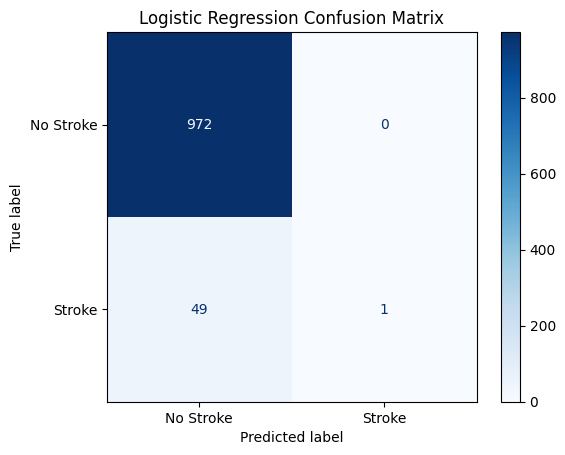

In [101]:
#confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_estimator(
    lr_model,
    X_test,
    y_test,
    display_labels=['No Stroke', 'Stroke'],
    cmap='Blues'
)

plt.title('Logistic Regression Confusion Matrix')
plt.show()


### Logistic Regression Model

Logistic Regression was implemented as the first classification algorithm.

The model was trained using the training dataset and evaluated using the test dataset.

Accuracy, precision, recall, F1-score, and ROC-AUC were calculated to assess model performance.

A confusion matrix was also generated to examine the classification results, particularly the model's ability to identify stroke cases.

In [102]:
#Train Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create Random Forest model
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")


Random Forest trained successfully!


In [103]:
#evaluate random forest model

# Make predictions
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_rf, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_rf, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))


Accuracy: 0.949119373776908
Precision: 0.3333333333333333
Recall: 0.04
F1 Score: 0.07142857142857142
ROC-AUC: 0.7804115226337449

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.33      0.04      0.07        50

    accuracy                           0.95      1022
   macro avg       0.64      0.52      0.52      1022
weighted avg       0.92      0.95      0.93      1022



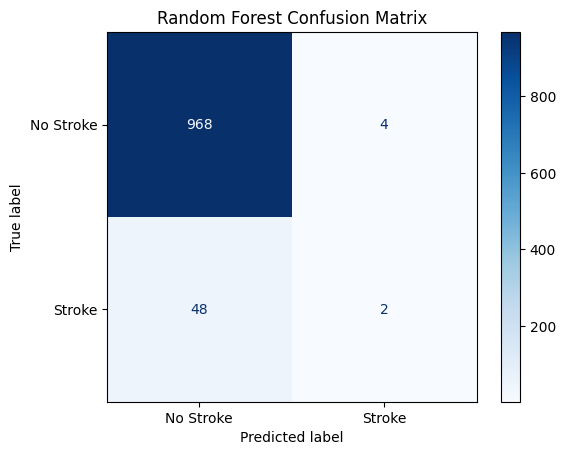

In [104]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_estimator(
    rf_model,
    X_test,
    y_test,
    display_labels=['No Stroke', 'Stroke'],
    cmap='Blues'
)

plt.title('Random Forest Confusion Matrix')
plt.show()


In [105]:
#Compare Logistic Regression vs Random Forest

import pandas as pd

comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

comparison.round(4)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9521,1.0000,0.02,0.0392,0.8417
1,Random Forest,0.9491,0.3333,0.04,0.0714,0.7804


### Random Forest Classification

A Random Forest classifier was implemented using 100 decision trees.

The model was trained on the training dataset and evaluated using the test dataset.

Accuracy, precision, recall, F1-score, and ROC-AUC were calculated and compared with the Logistic Regression model.

Special attention was given to recall because identifying stroke cases is important in this classification problem.

In [106]:
#Train SVM Model
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

# Create SVM model
svm_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(
        kernel='rbf',
        probability=True,
        random_state=42
    ))
])

# Train the model
svm_model.fit(X_train, y_train)

print("SVM Model trained successfully!")


SVM Model trained successfully!


In [107]:
# Make predictions
y_pred_svm = svm_model.predict(X_test)
y_prob_svm = svm_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_svm, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_svm, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm, zero_division=0))


Accuracy: 0.9510763209393346
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 0.6389917695473251

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022



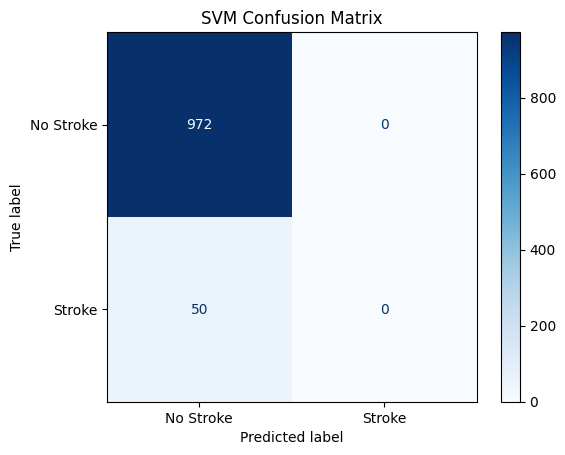

In [108]:
#SVM Confusion Matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_estimator(
    svm_model,
    X_test,
    y_test,
    display_labels=['No Stroke', 'Stroke'],
    cmap='Blues'
)

plt.title('SVM Confusion Matrix')
plt.show()


### Support Vector Machine (SVM) Classification

A Support Vector Machine classifier with a Radial Basis Function (RBF) kernel was implemented to predict stroke status.

The model was trained using the training dataset and evaluated on the testing dataset.

Accuracy, precision, recall, F1-score, and ROC-AUC were calculated to evaluate model performance.

A confusion matrix was generated to examine the model's classification results.

The results will be compared with Logistic Regression, Random Forest, and other classification algorithms.

In [109]:
#Train KNN Model
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

# Create KNN classification model
knn_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(
        n_neighbors=5,
        metric='minkowski',
        p=2
    ))
])

# Train the KNN model
knn_model.fit(X_train, y_train)

print("KNN Model trained successfully!")


KNN Model trained successfully!


In [110]:
#Evaluate KNN Model
# Make predictions
y_pred_knn = knn_model.predict(X_test)
y_prob_knn = knn_model.predict_proba(X_test)[:, 1]

# Calculate performance metrics
print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_knn, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_knn, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn, zero_division=0))


Accuracy: 0.9481409001956947
Precision: 0.0
Recall: 0.0
F1 Score: 0.0
ROC-AUC: 0.6214197530864197

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022



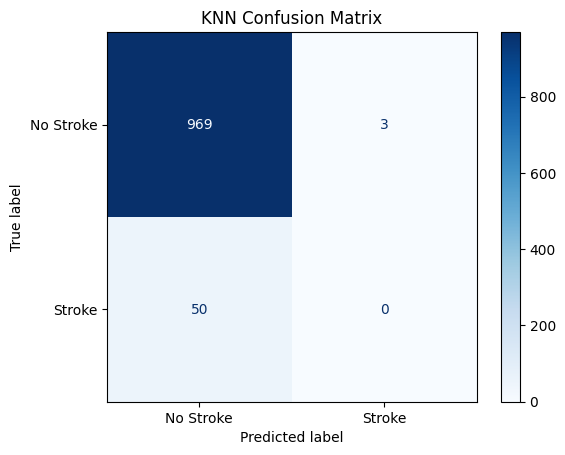

In [111]:
#Confusion Matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_estimator(
    knn_model,
    X_test,
    y_test,
    display_labels=['No Stroke', 'Stroke'],
    cmap='Blues'
)

plt.title('KNN Confusion Matrix')
plt.show()


### K-Nearest Neighbors (KNN) Classification

A K-Nearest Neighbors (KNN) classifier was implemented using five nearest neighbors (k = 5) and Euclidean distance.

The model was trained using the training dataset and evaluated using the testing dataset.

Accuracy, precision, recall, F1-score, and ROC-AUC were calculated to evaluate the model's performance.

A confusion matrix was generated to examine the classification results, particularly the detection of stroke cases.

Hyperparameter tuning will be performed later to identify suitable model parameters.

In [112]:
#Train Gradient Boosting Model
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

# Create Gradient Boosting model
gb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

# Train the model
gb_model.fit(X_train, y_train)

print("Gradient Boosting Model trained successfully!")


Gradient Boosting Model trained successfully!


In [113]:
#Evaluate Gradient Boosting Model
# Make predictions
y_pred_gb = gb_model.predict(X_test)
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

# Calculate performance metrics
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_gb, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred_gb, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_gb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_gb, zero_division=0))


Accuracy: 0.9510763209393346
Precision: 0.5
Recall: 0.04
F1 Score: 0.07407407407407407
ROC-AUC: 0.8342901234567901

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.50      0.04      0.07        50

    accuracy                           0.95      1022
   macro avg       0.73      0.52      0.52      1022
weighted avg       0.93      0.95      0.93      1022



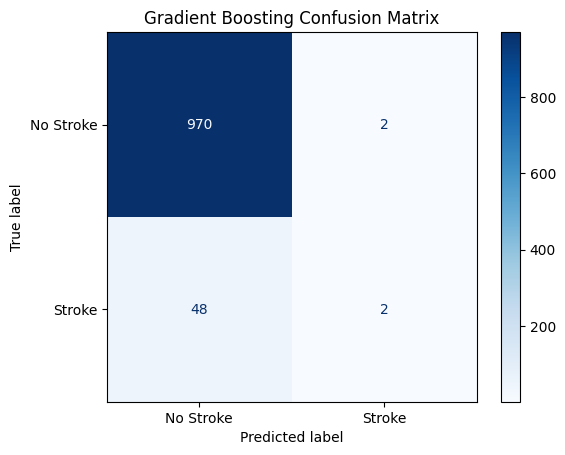

In [114]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Display confusion matrix
ConfusionMatrixDisplay.from_estimator(
    gb_model,
    X_test,
    y_test,
    display_labels=['No Stroke', 'Stroke'],
    cmap='Blues'
)

plt.title('Gradient Boosting Confusion Matrix')
plt.show()


### Gradient Boosting Classification

A Gradient Boosting classifier was implemented using 100 estimators, a learning rate of 0.1, and a maximum tree depth of 3.

The model was trained using the training dataset and evaluated using the testing dataset.

Accuracy, precision, recall, F1-score, and ROC-AUC were calculated to evaluate the model's performance.

A confusion matrix was generated to examine the classification results, particularly the model's ability to identify stroke cases.

The performance of Gradient Boosting will be compared with other classification algorithms to determine the most suitable model.

In [115]:
#Create Model Comparison Table

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Store the trained models
models = {
    'Logistic Regression': lr_model,
    'Random Forest': rf_model,
    'SVM': svm_model,
    'KNN': knn_model,
    'Gradient Boosting': gb_model
}

# Store evaluation results
results = []

# Evaluate each model
for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(
            y_test, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_test, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_test, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

# Create comparison DataFrame
comparison_df = pd.DataFrame(results)

# Display results
comparison_df.round(4)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9521,1.0000,0.02,0.0392,0.8417
1,Random Forest,0.9491,0.3333,0.04,0.0714,0.7804
2,SVM,0.9511,0.0000,0.00,0.0000,0.6390
3,KNN,0.9481,0.0000,0.00,0.0000,0.6214
4,Gradient Boosting,0.9511,0.5000,0.04,0.0741,0.8343


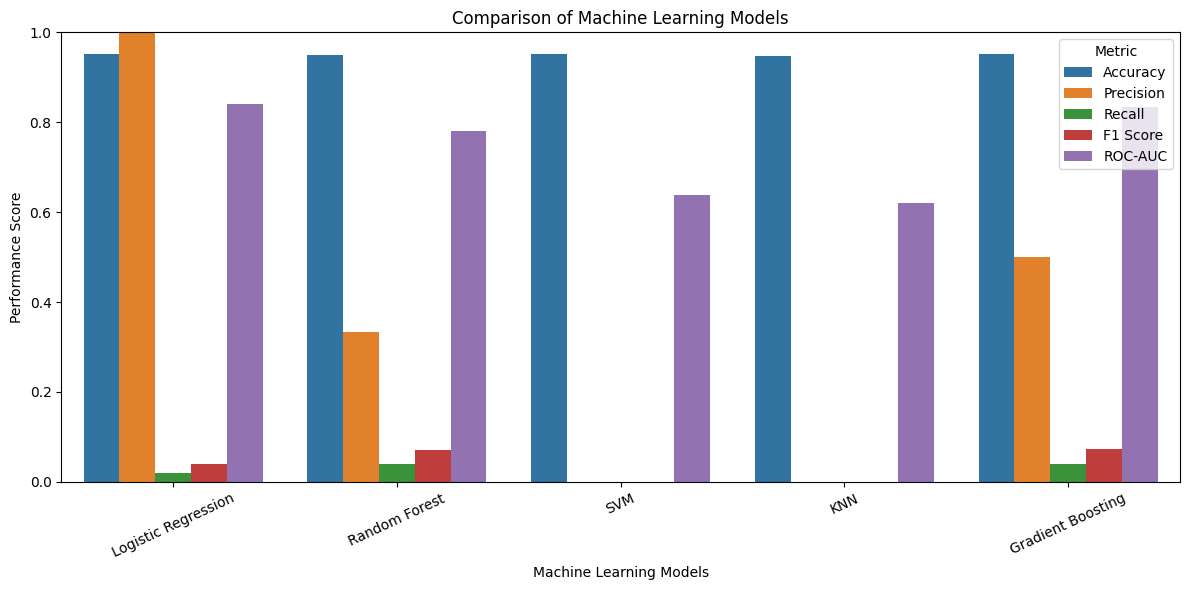

In [116]:
#Visualize Model Performance
import matplotlib.pyplot as plt
import seaborn as sns

# Convert results into long format
comparison_long = comparison_df.melt(
    id_vars='Model',
    value_vars=[
        'Accuracy', 'Precision', 'Recall',
        'F1 Score', 'ROC-AUC'
    ],
    var_name='Metric',
    value_name='Score'
)

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_long,
    x='Model',
    y='Score',
    hue='Metric'
)

plt.title('Comparison of Machine Learning Models')
plt.xlabel('Machine Learning Models')
plt.ylabel('Performance Score')
plt.ylim(0, 1)
plt.xticks(rotation=25)
plt.legend(title='Metric')
plt.tight_layout()
plt.show()


In [117]:
#Rank Models by Recall

# Rank models by stroke recall
recall_ranking = comparison_df.sort_values(
    by='Recall',
    ascending=False
)

recall_ranking.round(4)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
1,Random Forest,0.9491,0.3333,0.04,0.0714,0.7804
4,Gradient Boosting,0.9511,0.5000,0.04,0.0741,0.8343
0,Logistic Regression,0.9521,1.0000,0.02,0.0392,0.8417
2,SVM,0.9511,0.0000,0.00,0.0000,0.6390
3,KNN,0.9481,0.0000,0.00,0.0000,0.6214


### Comparison of Machine Learning Models

Five machine learning classification algorithms were evaluated: Logistic Regression, Random Forest, Support Vector Machine (SVM), K-Nearest Neighbors (KNN), and Gradient Boosting.

The models were compared using accuracy, precision, recall, F1-score, and ROC-AUC.

Since the dataset is highly imbalanced, accuracy alone may not provide a reliable assessment of stroke detection performance.

Therefore, special attention was given to recall, precision, and F1-score for the stroke class.

The test-set results were summarized in a comparison table and visualized using a bar chart. Cross-validation on the training data will be used to support model selection and hyperparameter tuning.

### Interpretation of Baseline Model Comparison

The five classification models achieved relatively high accuracy scores, ranging from 94.81% to 95.21%. However, their recall scores for the stroke class were extremely low, ranging from 0% to 4%.

Logistic Regression achieved the highest accuracy (95.21%) and ROC-AUC (0.8417). Gradient Boosting achieved the highest F1-score (0.0741), while Gradient Boosting and Random Forest both achieved a recall of 4%.

These results indicate that high accuracy does not necessarily reflect effective identification of stroke cases, particularly in an imbalanced dataset.

Therefore, further model evaluation using stratified cross-validation and class imbalance handling techniques is necessary before selecting and optimizing the final model.

In [118]:
#Define Cross-Validation

from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

# Define 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1 Score': 'f1',
    'ROC-AUC': 'roc_auc'
}

print("Cross-validation setup completed!")


Cross-validation setup completed!


In [119]:
#Perform Cross-Validation for All Models

# Store cross-validation results
cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        'Model': name,
        'Accuracy': scores['test_Accuracy'].mean(),
        'Precision': scores['test_Precision'].mean(),
        'Recall': scores['test_Recall'].mean(),
        'F1 Score': scores['test_F1 Score'].mean(),
        'ROC-AUC': scores['test_ROC-AUC'].mean()
    })

# Create comparison table
cv_comparison_df = pd.DataFrame(cv_results)

cv_comparison_df.round(4)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.9511,0.0000,0.0000,0.0000,0.8397
1,Random Forest,0.9511,0.2667,0.0100,0.0191,0.8049
2,SVM,0.9513,0.0000,0.0000,0.0000,0.6012
3,KNN,0.9472,0.1467,0.0201,0.0354,0.6149
4,Gradient Boosting,0.9496,0.3000,0.0201,0.0375,0.8426


In [120]:
# Rank models using cross-validation ROC-AUC
cv_ranking = cv_comparison_df.sort_values(
    by='ROC-AUC',
    ascending=False
)

cv_ranking.round(4)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
4,Gradient Boosting,0.9496,0.3000,0.0201,0.0375,0.8426
0,Logistic Regression,0.9511,0.0000,0.0000,0.0000,0.8397
1,Random Forest,0.9511,0.2667,0.0100,0.0191,0.8049
3,KNN,0.9472,0.1467,0.0201,0.0354,0.6149
2,SVM,0.9513,0.0000,0.0000,0.0000,0.6012


In [121]:
# Initial screening only (ROC-AUC). Final model is chosen later using Average Precision
best_model_name = cv_ranking.iloc[0]['Model']

print("Best Model:", best_model_name)
print(
    "Mean CV ROC-AUC:",
    round(cv_ranking.iloc[0]['ROC-AUC'], 4)
)

# Store the selected model
best_model = models[best_model_name]


Best Model: Gradient Boosting
Mean CV ROC-AUC: 0.8426


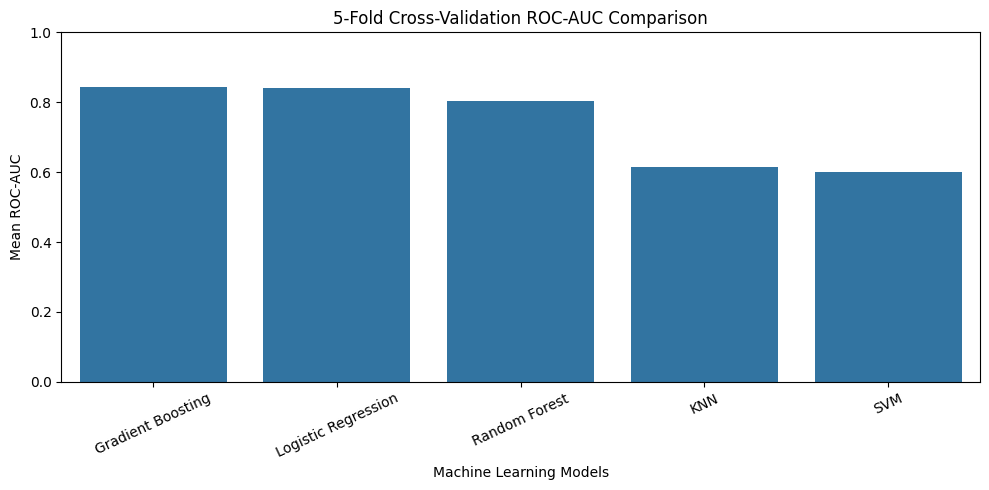

In [122]:
#Visualize Cross-Validation Results

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=cv_ranking,
    x='Model',
    y='ROC-AUC'
)

plt.title('5-Fold Cross-Validation ROC-AUC Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Mean ROC-AUC')
plt.ylim(0, 1)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


### Cross-Validation and Best Model Selection ###

Stratified 5-fold cross-validation was performed on the training dataset to evaluate the five machine learning classification models.

Stratification was used to preserve the proportion of stroke and non-stroke cases across the validation folds.

The models were evaluated using accuracy, precision, recall, F1-score, and ROC-AUC.

Mean cross-validation ROC-AUC was used as the primary criterion for selecting the best baseline model. Precision, recall, and F1-score were also considered due to the class imbalance in the dataset.

Preprocessing was performed within each cross-validation fold to prevent data leakage.

This ROC-AUC ranking is only an initial screening. Because the stroke class is rare, ROC-AUC can look good even when stroke detection is poor. The final model is therefore chosen later using Average Precision, which focuses on the minority class, across all approaches (no resampling, oversampling, class weighting).

In [123]:

# Install Imbalanced-Learn Library

%pip -q install imbalanced-learn


**Paper replication pipeline.** To compare fairly with the original study, this section follows the paper's preprocessing: mean imputation for BMI, Min-Max scaling, one-hot encoding, and random oversampling inside the training folds. Results here may differ slightly from the baseline section because of these preprocessing differences.

In [124]:

# Define Paper-Based Preprocessing

import numpy as np
import pandas as pd

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

from sklearn.preprocessing import (
    MinMaxScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

from sklearn.base import clone

# Set random state
RANDOM_STATE = 42

# Define cross-validation
CV = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Identify numerical and categorical columns
num_attribs = X_train.select_dtypes(
    include=np.number
).columns.tolist()

cat_attribs = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical preprocessing
num_pipeline = SkPipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', MinMaxScaler())
])

# Categorical preprocessing
cat_pipeline = SkPipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
paper_preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_attribs),
    ('cat', cat_pipeline, cat_attribs)
])

print("Paper-based preprocessing completed!")


Paper-based preprocessing completed!


In [125]:

#Define Machine Learning Models

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

paper_models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),

    'SVM': SVC(
        probability=True,
        random_state=RANDOM_STATE
    ),

    'KNN': KNeighborsClassifier(
        n_neighbors=5
    )
}

# Create model pipeline
def make_paper_model(estimator, resample=False):

    steps = [
        ('preprocess', clone(paper_preprocessor))
    ]

    if resample:
        steps.append((
            'oversample',
            RandomOverSampler(random_state=RANDOM_STATE)
        ))

    steps.append(('model', clone(estimator)))

    return ImbPipeline(steps)

print("Five models defined successfully!")


Five models defined successfully!


In [126]:
#Define Evaluation Metrics

paper_scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'average_precision': 'average_precision'
}

# Store cross-validation results
paper_cv_rows = []

# Compare without and with random oversampling
for scheme, use_ros in [
    ('No resampling', False),
    ('Random oversampling', True)
]:

    for name, estimator in paper_models.items():

        model = make_paper_model(
            estimator,
            resample=use_ros
        )

        scores = cross_validate(
            model,
            X_train,
            y_train,
            cv=CV,
            scoring=paper_scoring,
            n_jobs=-1
        )

        row = {
            'Scheme': scheme,
            'Model': name
        }

        for metric in paper_scoring:
            row[metric] = scores[
                'test_' + metric
            ].mean()

        paper_cv_rows.append(row)

# Create results table
paper_cv_results = pd.DataFrame(paper_cv_rows)

display(paper_cv_results.round(4))


,Scheme,Model,accuracy,precision,recall,f1,roc_auc,average_precision
0,No resampling,Logistic Regression,0.9513,0.0000,0.0000,0.0000,0.8393,0.1941
1,No resampling,Random Forest,0.9503,0.0000,0.0000,0.0000,0.8039,0.1555
2,No resampling,Gradient Boosting,0.9499,0.0900,0.0100,0.0180,0.8415,0.1903
3,No resampling,SVM,0.9513,0.0000,0.0000,0.0000,0.6467,0.1122
4,No resampling,KNN,0.9513,0.4333,0.0303,0.0563,0.5992,0.0892
5,Random oversampling,Logistic Regression,0.7407,0.1339,0.7891,0.2288,0.8379,0.1912
6,Random oversampling,Random Forest,0.9432,0.1842,0.0301,0.0508,0.8044,0.1580
7,Random oversampling,Gradient Boosting,0.7943,0.1472,0.6681,0.2411,0.8305,0.1962
8,Random oversampling,SVM,0.7551,0.1153,0.6029,0.1935,0.7723,0.1513
9,Random oversampling,KNN,0.8535,0.1069,0.2663,0.1521,0.5990,0.0712


In [127]:
# Define Improved Preprocessing

improved_preprocess = clone(paper_preprocessor)

print("Consistent preprocessing created!")


Consistent preprocessing created!


In [128]:
 #Define Class Weighted Models

improved_models = {

    'Weighted Logistic Regression':
    LogisticRegression(
        class_weight='balanced',
        max_iter=2000,
        random_state=RANDOM_STATE
    ),

    'Weighted Random Forest':
    RandomForestClassifier(
        class_weight='balanced',
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

print("Class weighted models defined!")


Class weighted models defined!


In [129]:
#Perform Cross-Validation

weighted_rows = []
weighted_pipes = {}

for name, estimator in improved_models.items():

    model = SkPipeline([
        ('preprocess', clone(improved_preprocess)),
        ('model', clone(estimator))
    ])

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=CV,
        scoring=paper_scoring,
        n_jobs=-1
    )

    row = {'Model': name}

    for metric in paper_scoring:
        row[metric] = scores[
            'test_' + metric
        ].mean()

    weighted_rows.append(row)
    weighted_pipes[name] = model

# Create comparison table
weighted_cv = pd.DataFrame(weighted_rows)

display(weighted_cv.round(4))


,Model,accuracy,precision,recall,f1,roc_auc,average_precision
0,Weighted Logistic Regression,0.7378,0.1325,0.7891,0.2269,0.8392,0.1919
1,Weighted Random Forest,0.9503,0.1000,0.0050,0.0095,0.8081,0.1559


### Interpretation of Class Weighting Results

Class weighting was investigated as an alternative
approach to handling class imbalance.

Weighted Logistic Regression achieved an accuracy
of 0.7378, precision of 0.1325, recall of 0.7891,
and an F1-score of 0.2269.

It also achieved a ROC-AUC of 0.8392 and an
Average Precision of 0.1919.

Weighted Random Forest achieved a higher accuracy
of 0.9503 but demonstrated extremely low recall
of 0.0050.

These findings indicate that class weighting
improved minority-class detection for Logistic
Regression but did not provide a similar
improvement for Random Forest.

Therefore, the effectiveness of class weighting
depends on the selected machine learning algorithm.

In [130]:
# Compare All Candidate Models

candidate_scores = {}
candidate_pipes = {}

# Add No Resampling models
for _, row in paper_cv_results[
    paper_cv_results['Scheme'] == 'No resampling'
].iterrows():

    name = 'No Resampling ' + row['Model']

    candidate_scores[name] = row['average_precision']

    candidate_pipes[name] = make_paper_model(
        paper_models[row['Model']],
        resample=False
    )


# Add Random Oversampling models
for _, row in paper_cv_results[
    paper_cv_results['Scheme'] == 'Random oversampling'
].iterrows():

    name = 'Oversampled ' + row['Model']

    candidate_scores[name] = row['average_precision']

    candidate_pipes[name] = make_paper_model(
        paper_models[row['Model']],
        resample=True
    )


# Add Class Weighted models
for _, row in weighted_cv.iterrows():

    name = row['Model']

    candidate_scores[name] = row['average_precision']

    candidate_pipes[name] = weighted_pipes[name]


# Rank all candidate models
ranked = pd.Series(
    candidate_scores,
    name='CV Average Precision'
).sort_values(ascending=False)

display(ranked.to_frame())


,CV Average Precision
Oversampled Gradient Boosting,0.196235
No Resampling Logistic Regression,0.194061
Weighted Logistic Regression,0.191899
Oversampled Logistic Regression,0.191244
No Resampling Gradient Boosting,0.190309
Oversampled Random Forest,0.158045
Weighted Random Forest,0.155904
No Resampling Random Forest,0.155507
Oversampled SVM,0.151288
No Resampling SVM,0.112241


### Interpretation of Model Ranking and Selection

The candidate models were ranked using
cross-validation Average Precision.

Average Precision was selected as the primary
evaluation metric because the dataset contains
a highly imbalanced target variable.

Oversampled Gradient Boosting achieved the
highest cross-validation Average Precision
of 0.1962.

Its Average Precision (0.1962) was only slightly higher than No Resampling Logistic Regression (0.1941), Weighted Logistic Regression (0.1919) and Oversampled Logistic Regression (0.1912). These differences are very small, so the top candidates perform similarly. Gradient Boosting was selected because it had the highest cross-validation Average Precision and can capture non-linear relationships between the clinical variables.

Therefore, Oversampled Gradient Boosting was
selected as the best candidate model for
hyperparameter tuning.

This selection was based on cross-validation
performance rather than test-set results,
preserving the independence of the final
test dataset.

In [131]:

#  Identify the Best Candidate Model

selected_name = ranked.index[0]

selected_pipe = candidate_pipes[selected_name]

print("Selected Model:", selected_name)

print(
    "Best CV Average Precision:",
    round(ranked.iloc[0], 4)
)


Selected Model: Oversampled Gradient Boosting
Best CV Average Precision: 0.1962


In [132]:
#HYPERPARAMETER TUNING
#Import Hyperparameter Tuning Methods

from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV
)

from scipy.stats import loguniform

print("Hyperparameter tuning methods imported!")


Hyperparameter tuning methods imported!


In [133]:

#Define Hyperparameter Search Space

if 'KNN' in selected_name:

    # KNN parameter grid - Lab 5.1 style
    param_grid = {
        'model__n_neighbors': [3, 5, 7, 9, 11, 15],
        'model__weights': ['uniform', 'distance'],
        'model__metric': [
            'euclidean',
            'manhattan',
            'minkowski'
        ]
    }

elif 'Logistic Regression' in selected_name:

    param_grid = {
        'model__C': loguniform(0.01, 100)
    }

elif 'Random Forest' in selected_name:

    param_grid = {
        'model__n_estimators': [100, 200, 300],
        'model__max_depth': [None, 4, 8, 12],
        'model__min_samples_leaf': [1, 2, 5, 10],
        'model__max_features': ['sqrt', 0.7]
    }

elif 'Gradient Boosting' in selected_name:

    param_grid = {
        'model__n_estimators': [50, 100, 150, 200],
        'model__learning_rate': [0.03, 0.05, 0.1, 0.2],
        'model__max_depth': [2, 3, 4],
        'model__subsample': [0.8, 1.0]
    }

elif 'SVM' in selected_name:

    param_grid = {
        'model__C': loguniform(0.1, 100),
        'model__gamma': ['scale', 0.01, 0.1, 1.0],
        'model__kernel': ['rbf']
    }

print("Parameter search space defined!")


Parameter search space defined!


In [134]:

#Perform Grid Search or Randomized Search

if 'KNN' in selected_name:

    # Grid Search for KNN
    search = GridSearchCV(
        selected_pipe,
        param_grid,
        cv=CV,
        scoring='average_precision',
        n_jobs=-1,
        refit=True
    )

else:

    # Randomized Search for other models
    search = RandomizedSearchCV(
        selected_pipe,
        param_distributions=param_grid,
        n_iter=12,
        scoring='average_precision',
        cv=CV,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True
    )

# Fit the search using training data
search.fit(X_train, y_train)

# Display best parameters
print("Best Parameters:")
print(search.best_params_)

print("\nBest Cross-Validation Score:")
print(round(search.best_score_, 4))

# Store tuned model
tuned_model = search.best_estimator_


Best Parameters:
{'model__subsample': 0.8, 'model__n_estimators': 50, 'model__max_depth': 4, 'model__learning_rate': 0.1}

Best Cross-Validation Score:
0.2073


### Interpretation of Hyperparameter Tuning

Randomized Search was used to optimize the
selected Gradient Boosting model.

The search was performed using stratified
five-fold cross-validation with Average
Precision as the scoring metric.

The best parameters were:

- Subsample: 0.8
- Number of estimators: 50
- Maximum depth: 4
- Learning rate: 0.1

The best cross-validation Average Precision
increased from 0.1962 to 0.2073 after tuning.

This indicates an improvement in the model's
cross-validation performance.

The tuned model was retained for final
evaluation using the untouched test dataset.

Because the best of 12 random combinations was chosen using the same cross-validation folds, the score of 0.2073 is likely slightly optimistic. The untouched test set gives the fairer estimate.

In [135]:

#THRESHOLD SELECTION
#Generate Out-of-Fold Predictions

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    accuracy_score,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay
)

# Generate training cross-validation probabilities
oof_probs = cross_val_predict(
    clone(tuned_model),
    X_train,
    y_train,
    cv=CV,
    method='predict_proba',
    n_jobs=-1
)[:, 1]

print("Out-of-fold probabilities generated!")


Out-of-fold probabilities generated!


In [136]:
#Find the Best Threshold Using F2 Score

threshold_grid = np.linspace(0.05, 0.95, 91)

threshold_rows = []

for threshold in threshold_grid:

    predictions = (
        oof_probs >= threshold
    ).astype(int)

    precision = precision_score(
        y_train,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_train,
        predictions,
        zero_division=0
    )

    # Calculate F2 score
    f2 = (
        (5 * precision * recall) /
        (4 * precision + recall)
        if (4 * precision + recall) > 0
        else 0
    )

    threshold_rows.append({
        'Threshold': threshold,
        'Precision': precision,
        'Recall': recall,
        'F2 Score': f2
    })

threshold_df = pd.DataFrame(threshold_rows)

# Select threshold with highest F2 score
chosen_threshold = float(
    threshold_df.loc[
        threshold_df['F2 Score'].idxmax(),
        'Threshold'
    ]
)

print("Selected Threshold:", chosen_threshold)

display(
    threshold_df.sort_values(
        by='F2 Score',
        ascending=False
    ).head(10).round(4)
)


Selected Threshold: 0.41999999999999993


,Threshold,Precision,Recall,F2 Score
37,0.42,0.1396,0.7638,0.4032
42,0.47,0.1480,0.6985,0.4006
44,0.49,0.1519,0.6734,0.3993
39,0.44,0.1420,0.7286,0.3990
38,0.43,0.1395,0.7437,0.3985
46,0.51,0.1545,0.6583,0.3984
36,0.41,0.1359,0.7688,0.3980
45,0.50,0.1530,0.6633,0.3978
30,0.35,0.1287,0.8191,0.3951
31,0.36,0.1295,0.8090,0.3948


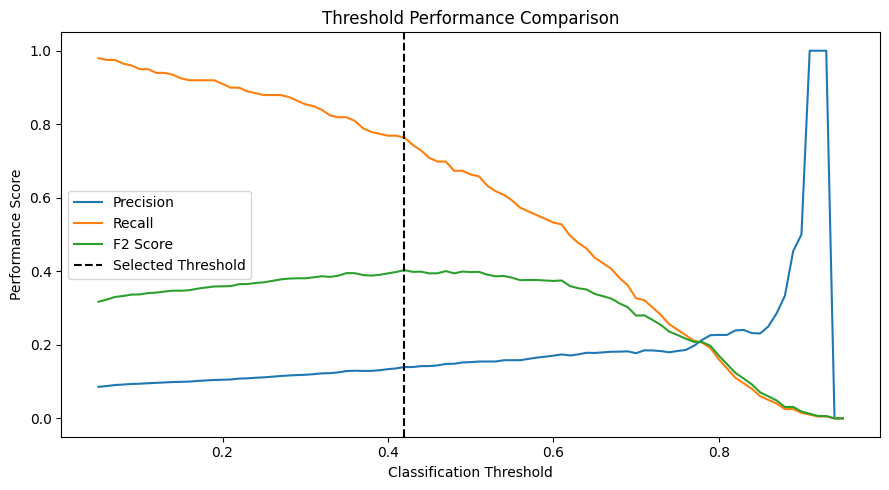

In [137]:
#Visualize Threshold Performance

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for metric in ['Precision', 'Recall', 'F2 Score']:

    plt.plot(
        threshold_df['Threshold'],
        threshold_df[metric],
        label=metric
    )

plt.axvline(
    chosen_threshold,
    linestyle='--',
    color='black',
    label='Selected Threshold'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Performance Score')
plt.title('Threshold Performance Comparison')

plt.legend()
plt.tight_layout()
plt.show()


In [138]:

# FINAL MODEL EVALUATION
# Predict Using the Untouched Test Dataset

# Get prediction probabilities
test_probs = tuned_model.predict_proba(X_test)[:, 1]

# Predictions using default threshold
pred_default = (
    test_probs >= 0.50
).astype(int)

# Predictions using selected threshold
pred_tuned = (
    test_probs >= chosen_threshold
).astype(int)

print("Final predictions completed!")


Final predictions completed!


In [139]:

# Compare Final Evaluation Metrics

from sklearn.metrics import fbeta_score

def metrics_row(label, predictions, probabilities):

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    return {
        'Approach': label,

        'Accuracy': accuracy_score(
            y_test, predictions
        ),

        'Precision': precision_score(
            y_test, predictions,
            zero_division=0
        ),

        'Recall': recall_score(
            y_test, predictions,
            zero_division=0
        ),

        'F1 Score': f1_score(
            y_test, predictions,
            zero_division=0
        ),

        'F2 Score': fbeta_score(
            y_test, predictions,
            beta=2,
            zero_division=0
        ),

        'ROC-AUC': roc_auc_score(
            y_test, probabilities
        ),

        'PR-AUC': average_precision_score(
            y_test, probabilities
        ),

        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp
    }


final_rows = [

    metrics_row(
        'Default Threshold (0.50)',
        pred_default,
        test_probs
    ),

    metrics_row(
        f'Selected Threshold ({chosen_threshold:.2f})',
        pred_tuned,
        test_probs
    )
]

final_table = pd.DataFrame(final_rows)

display(final_table.round(4))



,Approach,Accuracy,Precision,Recall,F1 Score,F2 Score,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,Default Threshold (0.50),0.8102,0.1727,0.76,0.2815,0.4524,0.8296,0.2259,790,182,12,38
1,Selected Threshold (0.42),0.7564,0.1434,0.80,0.2432,0.4175,0.8296,0.2259,733,239,10,40


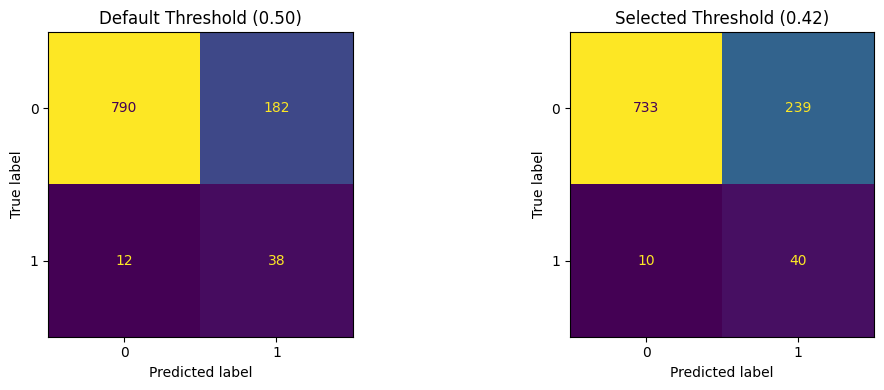

Default Threshold Report:
              precision    recall  f1-score   support

           0       0.99      0.81      0.89       972
           1       0.17      0.76      0.28        50

    accuracy                           0.81      1022
   macro avg       0.58      0.79      0.59      1022
weighted avg       0.95      0.81      0.86      1022

Selected Threshold Report:
              precision    recall  f1-score   support

           0       0.99      0.75      0.85       972
           1       0.14      0.80      0.24        50

    accuracy                           0.76      1022
   macro avg       0.56      0.78      0.55      1022
weighted avg       0.95      0.76      0.82      1022



In [140]:

#Display Confusion Matrices

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_default,
    ax=axes[0],
    colorbar=False
)

axes[0].set_title('Default Threshold (0.50)')

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_tuned,
    ax=axes[1],
    colorbar=False
)

axes[1].set_title(
    f'Selected Threshold ({chosen_threshold:.2f})'
)

plt.tight_layout()
plt.show()

# Classification reports
print("Default Threshold Report:")
print(
    classification_report(
        y_test,
        pred_default,
        zero_division=0
    )
)

print("Selected Threshold Report:")
print(
    classification_report(
        y_test,
        pred_tuned,
        zero_division=0
    )
)


### Interpretation of Threshold Optimization and Final Test Results

The threshold of 0.42 was selected using out-of-fold training predictions only, by maximizing the F2-score, before looking at the test set.

On the test set (50 stroke cases), compared with the default threshold of 0.50: recall increased from 0.76 to 0.80 (true positives 38 to 40, false negatives 12 to 10), precision decreased from 0.1727 to 0.1434, accuracy decreased from 0.8102 to 0.7564, false positives increased from 182 to 239, and F2 decreased from 0.4524 to 0.4175.

The lower threshold found 2 more strokes but added 57 more false alarms. This shows the trade-off between sensitivity and precision.

Since 0.42 was chosen using training data only, it is kept as the final operating point. With only 50 stroke cases in the test set, this small difference should not be over-interpreted. If false alarms are costly, the default 0.50 is a reasonable alternative.

In [141]:

#COMPARISON WITH ORIGINAL RESEARCH PAPER
# Define Published Research Results

published_results = pd.DataFrame([

    ('Logistic Regression', 0.9511, 0.84, 972, 0, 50, 0),

    ('Gradient Boosting', 0.9490, 0.82, 968, 4, 49, 1),

    ('SVM', 0.9512, 0.60, 972, 0, 50, 0),

    ('Random Forest', 0.9495, 0.80, 970, 2, 50, 0),

    ('KNN', 0.9418, 0.61, 969, 3, 49, 1)

], columns=[
    'Model',
    'Paper_Accuracy',
    'Paper_ROC_AUC',
    'Paper_TN',
    'Paper_FP',
    'Paper_FN',
    'Paper_TP'
])

display(published_results)


,Model,Paper_Accuracy,Paper_ROC_AUC,Paper_TN,Paper_FP,Paper_FN,Paper_TP
0,Logistic Regression,0.9511,0.84,972,0,50,0
1,Gradient Boosting,0.9490,0.82,968,4,49,1
2,SVM,0.9512,0.60,972,0,50,0
3,Random Forest,0.9495,0.80,970,2,50,0
4,KNN,0.9418,0.61,969,3,49,1


In [142]:

#Evaluate Five Models on Test Data

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

paper_test_rows = []

paper_test_predictions = {}

for name, estimator in paper_models.items():

    model = make_paper_model(
        estimator,
        resample=True
    )

    # Train the model
    model.fit(X_train, y_train)

    # Generate predictions
    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    # Calculate confusion matrix values
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    paper_test_predictions[name] = (
        predictions,
        probabilities
    )

    paper_test_rows.append({

        'Model': name,

        'Accuracy': accuracy_score(
            y_test, predictions
        ),

        'Precision': precision_score(
            y_test, predictions,
            zero_division=0
        ),

        'Recall': recall_score(
            y_test, predictions,
            zero_division=0
        ),

        'F1 Score': f1_score(
            y_test, predictions,
            zero_division=0
        ),

        'ROC-AUC': roc_auc_score(
            y_test, probabilities
        ),

        'PR-AUC': average_precision_score(
            y_test, probabilities
        ),

        'TN': tn,
        'FP': fp,
        'FN': fn,
        'TP': tp
    })

paper_test_results = pd.DataFrame(paper_test_rows)

display(paper_test_results.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,Logistic Regression,0.7427,0.1365,0.80,0.2332,0.8442,0.2649,719,253,10,40
1,Random Forest,0.9432,0.2500,0.08,0.1212,0.7798,0.1380,960,12,46,4
2,Gradient Boosting,0.7984,0.1579,0.72,0.2590,0.8141,0.2004,780,192,14,36
3,SVM,0.7583,0.1283,0.68,0.2159,0.7912,0.1764,741,231,16,34
4,KNN,0.8659,0.1345,0.32,0.1893,0.5999,0.0805,869,103,34,16


In [143]:
# Compare Cross-Validation Results with Original Paper

# Published results
published_cv = published_results[
    ['Model', 'Paper_Accuracy', 'Paper_ROC_AUC']
].copy()


# Our No Resampling Results
our_no_resampling = paper_cv_results[
    paper_cv_results['Scheme'] == 'No resampling'
][['Model', 'accuracy', 'roc_auc']]

our_no_resampling = our_no_resampling.rename(
    columns={
        'accuracy': 'Our_NoResampling_Accuracy',
        'roc_auc': 'Our_NoResampling_ROC_AUC'
    }
)


# Our Random Oversampling Results
our_oversampling = paper_cv_results[
    paper_cv_results['Scheme'] == 'Random oversampling'
][['Model', 'accuracy', 'roc_auc']]

our_oversampling = our_oversampling.rename(
    columns={
        'accuracy': 'Our_Oversampling_Accuracy',
        'roc_auc': 'Our_Oversampling_ROC_AUC'
    }
)


# Combine all results
cv_comparison = published_cv.merge(
    our_no_resampling,
    on='Model'
).merge(
    our_oversampling,
    on='Model'
)


# Calculate differences
cv_comparison['NoResampling_Accuracy_Difference'] = (
    cv_comparison['Our_NoResampling_Accuracy'] -
    cv_comparison['Paper_Accuracy']
)

cv_comparison['Oversampling_Accuracy_Difference'] = (
    cv_comparison['Our_Oversampling_Accuracy'] -
    cv_comparison['Paper_Accuracy']
)

display(cv_comparison.round(4))



,Model,Paper_Accuracy,Paper_ROC_AUC,Our_NoResampling_Accuracy,Our_NoResampling_ROC_AUC,Our_Oversampling_Accuracy,Our_Oversampling_ROC_AUC,NoResampling_Accuracy_Difference,Oversampling_Accuracy_Difference
0,Logistic Regression,0.9511,0.84,0.9513,0.8393,0.7407,0.8379,0.0002,-0.2104
1,Gradient Boosting,0.9490,0.82,0.9499,0.8415,0.7943,0.8305,0.0009,-0.1547
2,SVM,0.9512,0.60,0.9513,0.6467,0.7551,0.7723,0.0001,-0.1961
3,Random Forest,0.9495,0.80,0.9503,0.8039,0.9432,0.8044,0.0008,-0.0063
4,KNN,0.9418,0.61,0.9513,0.5992,0.8535,0.5990,0.0095,-0.0883


In [144]:
#Compare Test Confusion Matrix Results

our_test_cm = paper_test_results[
    ['Model', 'TN', 'FP', 'FN', 'TP', 'Recall']
]

confusion_comparison = published_results.merge(
    our_test_cm,
    on='Model',
    suffixes=('_Paper', '_Our')
)

display(confusion_comparison)


,Model,Paper_Accuracy,Paper_ROC_AUC,Paper_TN,Paper_FP,Paper_FN,Paper_TP,TN,FP,FN,TP,Recall
0,Logistic Regression,0.9511,0.84,972,0,50,0,719,253,10,40,0.80
1,Gradient Boosting,0.9490,0.82,968,4,49,1,780,192,14,36,0.72
2,SVM,0.9512,0.60,972,0,50,0,741,231,16,34,0.68
3,Random Forest,0.9495,0.80,970,2,50,0,960,12,46,4,0.08
4,KNN,0.9418,0.61,969,3,49,1,869,103,34,16,0.32


In [145]:
#Compare Initial Baseline Results with Paper

initial_baseline_results = pd.DataFrame([

    ('Logistic Regression', 0.9521, 0.8417),
    ('Random Forest', 0.9491, 0.7804),
    ('SVM', 0.9511, 0.6390),
    ('KNN', 0.9481, 0.6214),
    ('Gradient Boosting', 0.9511, 0.8343)

], columns=[
    'Model',
    'Initial_Accuracy',
    'Initial_ROC_AUC'
])

initial_comparison = published_results.merge(
    initial_baseline_results,
    on='Model'
)

initial_comparison['Accuracy_Difference'] = (
    initial_comparison['Initial_Accuracy'] -
    initial_comparison['Paper_Accuracy']
)

initial_comparison['ROC_AUC_Difference'] = (
    initial_comparison['Initial_ROC_AUC'] -
    initial_comparison['Paper_ROC_AUC']
)

display(initial_comparison.round(4))


,Model,Paper_Accuracy,Paper_ROC_AUC,Paper_TN,Paper_FP,Paper_FN,Paper_TP,Initial_Accuracy,Initial_ROC_AUC,Accuracy_Difference,ROC_AUC_Difference
0,Logistic Regression,0.9511,0.84,972,0,50,0,0.9521,0.8417,0.0010,0.0017
1,Gradient Boosting,0.9490,0.82,968,4,49,1,0.9511,0.8343,0.0021,0.0143
2,SVM,0.9512,0.60,972,0,50,0,0.9511,0.6390,-0.0001,0.0390
3,Random Forest,0.9495,0.80,970,2,50,0,0.9491,0.7804,-0.0004,-0.0196
4,KNN,0.9418,0.61,969,3,49,1,0.9481,0.6214,0.0063,0.0114


# Comparison with the Original Research Paper

The experimental findings were compared with
the results reported by Akinwumi et al. (2025).

The initial models without resampling achieved
accuracy values close to those reported in
the original study.

For example, Logistic Regression achieved
an accuracy of 0.9513 and a ROC-AUC of 0.8393,
compared with the paper's reported accuracy
of 0.9511 and ROC-AUC of 0.84.

Similarly, Gradient Boosting achieved a
ROC-AUC of 0.8415 compared with 0.82
reported in the paper.

However, differences were observed in
the results obtained after applying
Random Oversampling.

In this experiment, Random Oversampling
substantially improved stroke detection
for Logistic Regression, Gradient Boosting,
SVM, and KNN.

For example, Logistic Regression achieved
a recall of 0.80 on the test dataset,
while Gradient Boosting achieved a recall
of 0.72.

In comparison, the original paper reported
very limited detection of stroke cases.
Logistic Regression, SVM and Random Forest detected no
true positive cases, while Gradient Boosting
and KNN detected only one each.

The main difference is in stroke detection. The paper reports that it also used random oversampling, yet its confusion matrices show almost no stroke predictions (Logistic Regression, SVM and Random Forest had 0 true positives), which looks like our no-resampling baseline. In our implementation, oversampling is applied only to the training folds inside the pipeline, and our Logistic Regression then found 40 of the 50 strokes (recall 0.80). The cost is that accuracy fell from about 95% to 74% (0.7427) because false positives rose from 0 to 253. The paper's high accuracy therefore mostly reflects predicting "no stroke" for almost everyone, while our lower accuracy reflects a model that actually tries to detect strokes. The paper does not give enough detail to say exactly why its recall stayed so low; one possible reason is how and where the oversampling was applied. Remaining small differences, for example SVM ROC-AUC 0.6467 against 0.60 in the paper, are likely due to the random split, random seeds and default hyperparameters.

Furthermore, this implementation performs
oversampling within the training folds,
preventing information from validation
data from entering the resampling process.

Therefore, the results demonstrate both
similarities with the original study and
potential improvements in minority-class
detection through appropriate class
imbalance handling.

However, the experiments should be
considered a methodological comparison
rather than an exact reproduction of
every experimental setting in the paper.

In [146]:

# FEATURE IMPORTANCE
# Train Random Forest for Feature Importance

rf_feature_model = make_paper_model(
    RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    resample=True
)

# Train the model
rf_feature_model.fit(X_train, y_train)

print("Random Forest feature model trained!")


Random Forest feature model trained!


In [147]:
# Calculate Feature Importance Scores

# Get transformed feature names
feature_names = (
    rf_feature_model
    .named_steps['preprocess']
    .get_feature_names_out()
)

# Get feature importance values
importances = pd.Series(
    rf_feature_model
    .named_steps['model']
    .feature_importances_,
    index=feature_names
)

# Rank features
feature_ranking = importances.sort_values(
    ascending=False
)

# Display top 15 features
display(
    feature_ranking.head(15).to_frame(
        'Importance Score'
    )
)


,Importance Score
num__age,0.379028
num__avg_glucose_level,0.189494
num__bmi,0.170621
num__hypertension,0.031624
cat__ever_married_Yes,0.023849
cat__ever_married_No,0.020426
num__heart_disease,0.020279
cat__smoking_status_never smoked,0.016460
cat__work_type_Self-employed,0.015496
cat__work_type_Private,0.015188


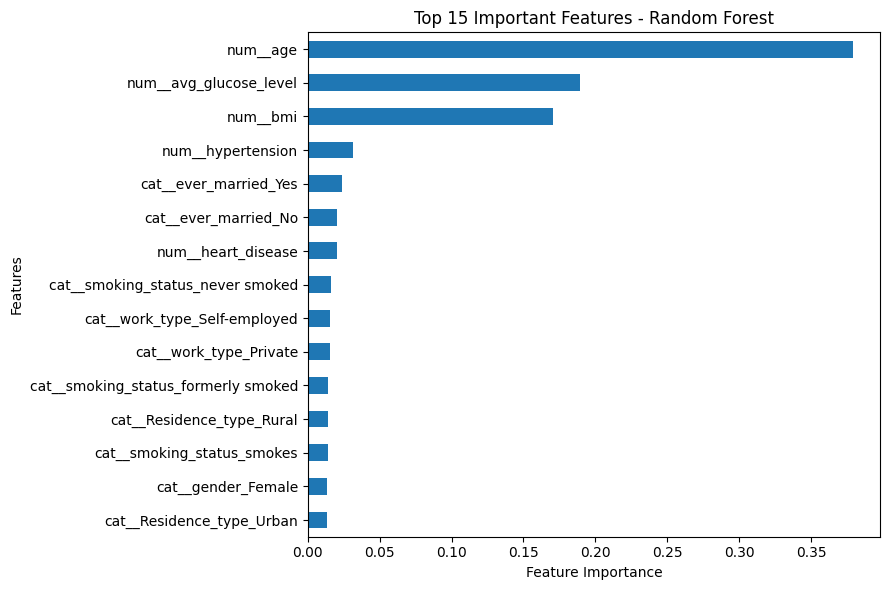

In [148]:
#FEATURE IMPORTANCE
#Visualize Top 15 Important Features

top_features = feature_ranking.head(15).sort_values()

plt.figure(figsize=(9, 6))

top_features.plot(kind='barh')

plt.title('Top 15 Important Features - Random Forest')
plt.xlabel('Feature Importance')
plt.ylabel('Features')

plt.tight_layout()
plt.show()


### Interpretation of Feature Importance

Random Forest feature importance analysis
was conducted to identify the most influential
variables in stroke prediction.

Age was identified as the most important
feature, with an importance score of 0.3790.

Average glucose level was the second most
important feature, with a score of 0.1895.

BMI was ranked third, with an importance
score of 0.1706.

These three variables collectively
contributed approximately 73.9% of the
total feature importance.

The findings are consistent with the
original research paper, which also
identified age, average glucose level,
and BMI as the most influential predictors.

This analysis provides useful insights into
the variables contributing to model predictions.

However, feature importance indicates
predictive contribution rather than
a causal relationship with stroke.

# Discussion

This study investigated five supervised machine
learning algorithms for stroke prediction using
demographic, clinical, and lifestyle variables.

The exploratory data analysis revealed that
the dataset contained 5,110 observations,
including 249 stroke cases and 4,861
non-stroke cases.

This represents a significant class imbalance,
with only 4.87% of observations belonging
to the stroke class.

The initial model comparison demonstrated
that all five algorithms achieved relatively
high accuracy values. However, their ability
to identify stroke cases was limited, as
the recall values were very low.

These findings indicate that accuracy alone
is not a sufficient measure of performance
for this imbalanced classification problem.

Random Oversampling was introduced to improve
minority-class detection. The results showed
improved recall for several algorithms.

Among the oversampled models, Gradient
Boosting achieved the highest cross-validation
Average Precision of 0.1962.

Class weighting was also investigated as
an alternative approach. Weighted Logistic
Regression achieved a recall of 0.7891
and an Average Precision of 0.1919.

However, Weighted Random Forest demonstrated
very low recall, indicating that class
weighting did not improve every algorithm
equally.

Based on the cross-validation Average
Precision, Oversampled Gradient Boosting
was selected as the best candidate model.

Hyperparameter tuning increased its
cross-validation Average Precision from
0.1962 to 0.2073.

The selected model was further evaluated
using an untouched test dataset.

Threshold optimization was performed using
out-of-fold training predictions. A threshold
of 0.42 was selected based on the highest
training out-of-fold F2-score.

At this threshold, test recall increased
from 0.76 to 0.80. However, precision
decreased from 0.1727 to 0.1434, while
false-positive predictions increased.

The results demonstrate that improving
minority-class detection involves a trade-off
between recall, precision, and overall accuracy.

Comparison with the original research paper
showed that the initial model performance
was relatively similar in terms of accuracy
and ROC-AUC.

However, the oversampling experiments
demonstrated improved identification of
stroke cases for several algorithms.

Random Forest feature importance analysis
identified age, average glucose level,
and BMI as the most influential predictors.

These findings were consistent with the
original research study.

Overall, the experiments highlight the
importance of appropriate preprocessing,
class imbalance handling, model selection,
and evaluation using multiple performance
metrics rather than relying solely on accuracy.

# Conclusion

This project investigated the performance
of five machine learning algorithms for
stroke prediction using the Stroke Prediction
Dataset.

The algorithms included Logistic Regression,
Random Forest, Gradient Boosting, Support
Vector Machine, and K-Nearest Neighbours.

Exploratory data analysis identified
significant class imbalance, with stroke
cases representing only 4.87% of the dataset.

The initial model evaluation demonstrated
that high accuracy does not necessarily
indicate effective detection of stroke cases.

Random Oversampling and Class Weighting
were investigated to address the class
imbalance problem.

Among the evaluated candidates, Oversampled
Gradient Boosting achieved the highest
cross-validation Average Precision of 0.1962.

Hyperparameter tuning further improved
the cross-validation score to 0.2073.

Threshold optimization increased the
test-set recall from 0.76 to 0.80,
although this improvement was accompanied
by lower precision and accuracy.

Feature importance analysis identified
age, average glucose level, and BMI as
the most influential predictors.

The experimental findings demonstrate
that appropriate class imbalance handling
and model optimization can improve the
identification of minority-class observations.

The study also highlights the importance
of evaluating machine learning models
using multiple performance metrics.

Further research using larger and more
diverse datasets is necessary to establish
the generalizability of these findings.

# Limitations

Several limitations should be considered
when interpreting the findings of this study.

1. The dataset contains a relatively small
   number of stroke cases compared with
   non-stroke observations.

2. The dataset may not fully represent
   different clinical populations.

3. Despite applying Random Oversampling
   and Class Weighting, precision remained
   relatively low for several models.

4. Improving recall resulted in an increase
   in false-positive predictions.

5. Differences in preprocessing, model
   configurations, data partitioning, and
   evaluation procedures may have influenced
   comparisons with the original paper.

6. Hyperparameter selection and threshold
   optimization were based on the available
   training dataset. A nested cross-validation
   approach could provide a stronger estimate
   of generalization performance.

7. Random Forest feature importance identifies
   predictive contributions but does not
   establish causal relationships.

8. External validation using independent
   clinical datasets was not performed.

Therefore, the developed models should be
considered experimental research models
rather than clinically validated diagnostic tools.

# References

1. Akinwumi, P. O., Ojo, S., Nathaniel, T. I.,
   Wanliss, J., Karunwi, O., & Sulaiman, M. (2025).
   Evaluating machine learning models for stroke
   prediction based on clinical variables.
   Frontiers in Neurology, 16, 1668420.
   https://doi.org/10.3389/fneur.2025.1668420

2. Soriano, F. (2021).
   Stroke Prediction Dataset.
   Kaggle.
   https://www.kaggle.com/datasets/fedesoriano/
   stroke-prediction-dataset

3. Scikit-learn Developers.
   Scikit-learn: Machine Learning in Python.
   https://scikit-learn.org/

4. Imbalanced-learn Developers.
   Imbalanced-learn Documentation.
   https://imbalanced-learn.org/